In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
df=pd.read_csv(r"C:\Users\Tejaswini\Downloads\archive (4)\Mall_Customers.csv")
print(df.shape)
print(df.head())
print(df.describe())
print("Missing values :",df.isnull().sum().sum())

(200, 5)
   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40
       CustomerID         Age  Annual Income (k$)  Spending Score (1-100)
count  200.000000  200.000000          200.000000              200.000000
mean   100.500000   38.850000           60.560000               50.200000
std     57.879185   13.969007           26.264721               25.823522
min      1.000000   18.000000           15.000000                1.000000
25%     50.750000   28.750000           41.500000               34.750000
50%    100.500000   36.000000           61.500000               50.000000
75%    150.250000   49.000000           78.0000

In [9]:
features=["Annual Income (k$)","Spending Score (1-100)"]
x=df[features]
scaler=StandardScaler()
x_scaled=scaler.fit_transform(x)

K= 2 inertia=  269.69 silhouette=0.321
K= 3 inertia=  157.70 silhouette=0.467
K= 4 inertia=  108.92 silhouette=0.494
K= 5 inertia=   65.57 silhouette=0.555
K= 6 inertia=   55.06 silhouette=0.540
K= 7 inertia=   44.86 silhouette=0.528
K= 8 inertia=   37.23 silhouette=0.455
K= 9 inertia=   32.39 silhouette=0.457
K=10 inertia=   29.98 silhouette=0.443


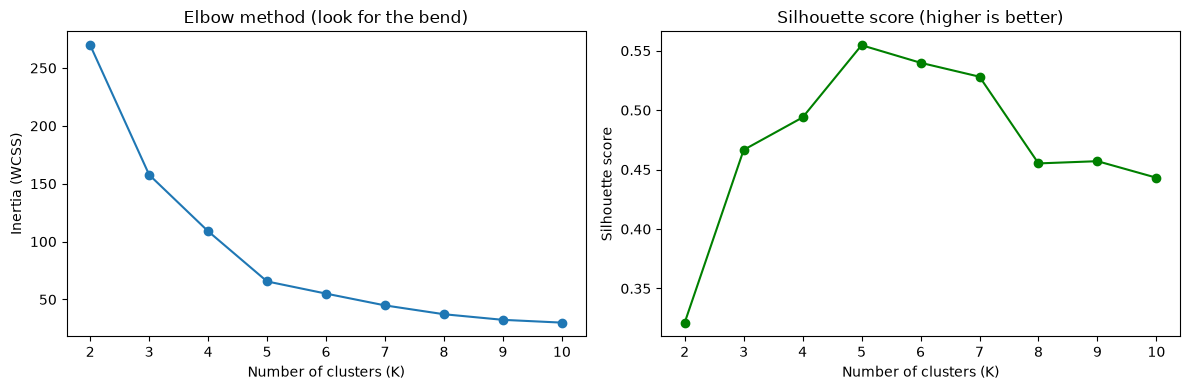

In [13]:
k_values = range(2, 11)
inertias = []
silhouettes = []

for k in k_values:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    km.fit(x_scaled)

    inertias.append(km.inertia_)  # Corrected
    silhouettes.append(silhouette_score(x_scaled, km.labels_))

    print(f"K={k:2d} inertia={km.inertia_:8.2f} silhouette={silhouettes[-1]:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

# Elbow Method
ax[0].plot(list(k_values), inertias, marker="o")  # corrected marker
ax[0].set_xlabel("Number of clusters (K)")
ax[0].set_ylabel("Inertia (WCSS)")
ax[0].set_title("Elbow method (look for the bend)")

# Silhouette Score
ax[1].plot(list(k_values), silhouettes, marker="o", color="green")
ax[1].set_xlabel("Number of clusters (K)")
ax[1].set_ylabel("Silhouette score")
ax[1].set_title("Silhouette score (higher is better)")

plt.tight_layout()
plt.show()

In [15]:



# 4. FIT THE FINAL MODEL

best_k = 5  # Choose from the elbow & silhouette plots

kmeans = KMeans(n_clusters=best_k, n_init=10, random_state=42)

df["Cluster"] = kmeans.fit_predict(x_scaled)

print("\nCustomers per cluster:\n",
      df["Cluster"].value_counts().sort_index())

print("Final silhouette score:",
      round(silhouette_score(x_scaled, df["Cluster"]), 3))





Customers per cluster:
 Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64
Final silhouette score: 0.555


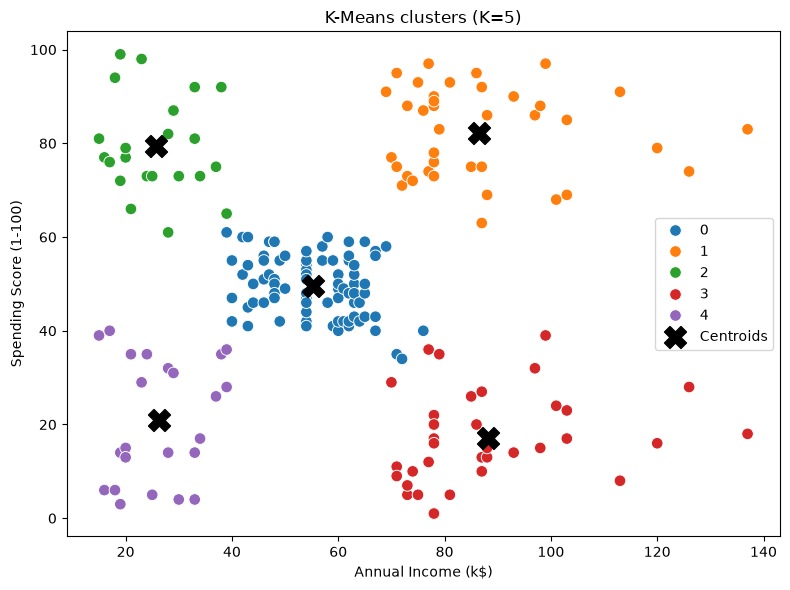

In [16]:
# ---------------------------------------------------------------
# 5. VISUALIZE THE CLUSTERS
# ---------------------------------------------------------------

# Centroids were learned in scaled space, so convert them back to real units
centroids = scaler.inverse_transform(kmeans.cluster_centers_)

plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df, x=features[0], y=features[1],
    hue="Cluster", palette="tab10", s=70
)

plt.scatter(
    centroids[:, 0], centroids[:, 1],
    marker="X", s=250, c="black", label="Centroids"
)

plt.title(f"K-Means clusters (K={best_k})")
plt.legend()
plt.tight_layout()
plt.show()